# 50 Startups: Multiple Linear Regression & Feature Selection (CRISP-DM)
### Course Project / Assignment: AIoT-DIC2-MultipleLR
**Topics Covered:**
1. **Part 1 (CRISP-DM Standard Pipeline)**: Multiple Linear Regression predicting Startup Profit.
2. **Part 2 (Feature Selection & Multi-Model Workflow)**: Forward Stepwise Selection ($k=1 \dots 5$) & Multi-Regression Model Comparison.

---
### 🌟 Bonus Criteria Implemented:
* **+1 Point**: Interactive Dropdown Selector between **Problem 1 (CRISP-DM Multiple Linear Regression)** and **Problem 2 (Feature Selection & Multi-Model Comparison)**.
* **+2 Points**: Dynamic Dataset URL Input allowing arbitrary CSV sources (such as `https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv` or Gist/GitHub raw links).


In [1]:
import pandas as pd
import numpy as np
import requests
from io import StringIO
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

# Configure Plot Styles
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
print("All required packages imported successfully!")


All required packages imported successfully!


## 🎛️ Interactive Control Panel (Dropdown & Custom Dataset URL)
> **加分功能展示**:
> 1. **下拉選單 (Dropdown)**: 可自由切換 **Problem 1 (CRISP-DM Multiple Linear Regression)** 與 **Problem 2 (Feature Selection & Multi-Model Workflow)**。
> 2. **任意輸入 Dataset URL**: 可自訂輸入 CSV 資料集網址並點擊執行。


In [2]:
# Define Interactive Widgets
dropdown_problem = widgets.Dropdown(
    options=[
        ('Problem 1: CRISP-DM Multiple Linear Regression (50 Startups)', 'p1'),
        ('Problem 2: Feature Selection & Multi-Model Comparison', 'p2')
    ],
    value='p1',
    description='選擇題目:',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='600px')
)

input_url = widgets.Text(
    value='https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv',
    description='Dataset URL:',
    placeholder='輸入 CSV 網址...',
    style={'description_width': 'initial'},
    layout=widgets.Layout(width='850px')
)

btn_run = widgets.Button(
    description='執行分析 (Run Analysis)',
    button_style='primary',
    icon='play',
    layout=widgets.Layout(width='220px', height='38px')
)

output_area = widgets.Output()

display(widgets.VBox([dropdown_problem, input_url, btn_run, output_area]))


## 📋 Part 1: CRISP-DM Methodology Implementation

CRISP-DM (Cross-Industry Standard Process for Data Mining) consists of 6 phases:
1. **Business Understanding**: Predict startup profit based on R&D spend, Administration, Marketing spend, and State location.
2. **Data Understanding**: Ingestion via HTTP GET, schema inspection, missing values check.
3. **Data Preparation**: One-hot encoding categorical variables (`State`), avoiding dummy variable trap, train/test splitting.
4. **Modeling**: Multiple Linear Regression with OLS (`LinearRegression`).
5. **Evaluation**: $R^2$, MAE, MSE, RMSE.
6. **Deployment & Visualization**: Actual vs. Predicted scatter plot.


In [3]:
def run_problem_1(dataset_url):
    print("=" * 70)
    print("🚀 [Part 1] CRISP-DM Multiple Linear Regression Analysis")
    print("=" * 70)

    # Phase 1 & 2: Business & Data Understanding (Data Acquisition)
    print(f"\n📥 [Phase 1 & 2] Fetching dataset from: {dataset_url}")
    data = None
    try:
        import urllib3
        urllib3.disable_warnings()
        resp = requests.get(dataset_url, verify=False, timeout=15)
        if resp.status_code == 200:
            data = pd.read_csv(StringIO(resp.text))
            print("✅ Data successfully loaded from web into Pandas DataFrame.")
        else:
            print(f"⚠️ Web returned status code: {resp.status_code}, attempting local fallback...")
    except Exception as e:
        print(f"⚠️ Network retrieval warning: {e}, attempting local fallback...")

    if data is None:
        try:
            data = pd.read_csv("50_Startups.csv")
            print("✅ Data loaded from local 50_Startups.csv fallback.")
        except Exception as e:
            print(f"❌ Failed to load dataset: {e}")
            return

    print(f"Dataset Shape: {data.shape[0]} rows, {data.shape[1]} columns")
    print("\n--- First 5 Rows ---")
    print(data.head())
    print("\n--- Column Names & Types ---")
    print(data.dtypes)
    print("\n--- Missing Values ---")
    print(data.isnull().sum())

    # Phase 3: Data Preparation
    print("\n🛠️ [Phase 3] Data Preparation")
    target_col = 'Profit' if 'Profit' in data.columns else data.columns[-1]
    X_raw = data.drop(target_col, axis=1)
    y = data[target_col]

    # Identify categorical columns
    cat_cols = X_raw.select_dtypes(include=['object', 'category']).columns.tolist()
    print(f"Target variable: '{target_col}'")
    print(f"Categorical features to encode: {cat_cols}")

    # One-Hot Encoding with Dummy Variable Trap avoidance
    if len(cat_cols) > 0:
        cat_idx = [X_raw.columns.get_loc(c) for c in cat_cols]
        ct = ColumnTransformer(
            transformers=[('encoder', OneHotEncoder(drop='first'), cat_idx)],
            remainder='passthrough'
        )
        X = ct.fit_transform(X_raw)
        print(f"✅ OneHotEncoder applied (dummy variable trap avoided by dropping first category). Transformed features shape: {X.shape}")
    else:
        X = X_raw.values

    # Split into Train and Test sets (80/20, random_state=0)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
    print(f"Train set size: {X_train.shape[0]}, Test set size: {X_test.shape[0]}")

    # Phase 4: Modeling
    print("\n🧠 [Phase 4] Modeling: Multiple Linear Regression")
    regressor = LinearRegression()
    regressor.fit(X_train, y_train)
    print("✅ Model training complete.")
    print(f"Intercept (β₀): {regressor.intercept_:.4f}")
    print(f"Coefficients (β): {regressor.coef_}")

    # Phase 5: Evaluation
    print("\n📊 [Phase 5] Evaluation Metrics")
    y_pred = regressor.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)

    print(f"  • R-squared (R²):           {r2:.6f}")
    print(f"  • Mean Absolute Error (MAE): {mae:.2f}")
    print(f"  • Mean Squared Error (MSE):  {mse:.2e}")
    print(f"  • Root Mean Squared Error:   {rmse:.2f}")

    # Phase 6: Visualization
    print("\n📈 [Phase 6] Visualization: Actual vs. Predicted Profit")
    plt.figure(figsize=(8, 6))
    plt.scatter(y_test, y_pred, color='#3b82f6', edgecolors='black', s=80, alpha=0.85, label='Test Data Predictions')

    # Ideal fit diagonal line
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit (y = x)')

    plt.xlabel('Actual Profit ($)', fontsize=12, fontweight='bold')
    plt.ylabel('Predicted Profit ($)', fontsize=12, fontweight='bold')
    plt.title('Actual vs Predicted Profit (Multiple Linear Regression)', fontsize=14, fontweight='bold')
    plt.legend(frameon=True)
    plt.tight_layout()
    plt.show()


## 🔬 Part 2: Feature Selection (Forward Stepwise) & Multi-Model Comparison Workflow
**Objectives:**
1. **Forward Selection**: Iteratively select features for $k=1 \dots 5$ by minimizing RMSE and maximizing $R^2$.
2. **Results Compilation**: Output Markdown table matching assignment requirements:
   `[Number of Features, Selected Features, RMSE, R-squared]`
3. **Dual Plot**: Dual chart of "RMSE by Number of Features" and "R-squared by Number of Features".
4. **Multi-Model Regression Comparison**: Compare Random Forest, Gradient Boosting, SVR, Ridge, LASSO, Elastic Net, and Linear Regression with MSE-sorted summary table and prediction curves.


In [4]:
def run_problem_2(dataset_url):
    print("=" * 70)
    print("🔬 [Part 2] Forward Feature Selection & Multi-Model Comparison Workflow")
    print("=" * 70)

    # 1. Data Loading
    print(f"\n📥 Loading dataset from: {dataset_url}")
    df = None
    try:
        import urllib3
        urllib3.disable_warnings()
        resp = requests.get(dataset_url, verify=False, timeout=15)
        if resp.status_code == 200:
            df = pd.read_csv(StringIO(resp.text))
            print("✅ Data successfully loaded from web.")
        else:
            print(f"⚠️ Web status: {resp.status_code}, trying local fallback...")
    except Exception as e:
        print(f"⚠️ Network warning: {e}, trying local fallback...")

    if df is None:
        try:
            df = pd.read_csv("50_Startups.csv")
            print("✅ Data loaded from local 50_Startups.csv fallback.")
        except Exception as e:
            print(f"❌ Failed to load: {e}")
            return

    # One-hot encode categorical features
    df_encoded = pd.get_dummies(df, columns=['State'], drop_first=True, dtype=float) if 'State' in df.columns else df.copy()
    target_col = 'Profit' if 'Profit' in df_encoded.columns else df_encoded.columns[-1]

    X_full = df_encoded.drop(target_col, axis=1)
    y_full = df_encoded[target_col]

    X_train, X_test, y_train, y_test = train_test_split(X_full, y_full, test_size=0.2, random_state=0)

    # 2. Forward Feature Selection Algorithm (k = 1 to 5)
    print("\n⚙️ Executing Forward Selection Algorithm (k = 1 to 5)...")
    candidate_features = list(X_full.columns)

    selected_features = []
    progression_records = []

    max_k = min(5, len(candidate_features))
    for k in range(1, max_k + 1):
        best_rmse = float('inf')
        best_feat = None
        best_r2 = -float('inf')

        for feat in candidate_features:
            if feat in selected_features:
                continue
            curr_feats = selected_features + [feat]
            model = LinearRegression().fit(X_train[curr_feats], y_train)
            pred = model.predict(X_test[curr_feats])
            rmse = np.sqrt(mean_squared_error(y_test, pred))
            r2 = r2_score(y_test, pred)

            if rmse < best_rmse:
                best_rmse = rmse
                best_feat = feat
                best_r2 = r2

        selected_features.append(best_feat)
        progression_records.append({
            'Number of Features': k,
            'Selected Features': str(selected_features),
            'RMSE': best_rmse,
            'R-squared': best_r2
        })

    results_df = pd.DataFrame(progression_records)

    # 3. Display Markdown Table
    print("\n📋 Markdown Results Table (Forward Selection):")
    md_table = "| Number of Features | Selected Features | RMSE | R-squared |\n|---|---|---|---|\n"
    for _, row in results_df.iterrows():
        md_table += f"| {row['Number of Features']} | `{row['Selected Features']}` | {row['RMSE']:.6f} | {row['R-squared']:.6f} |\n"
    display(Markdown(md_table))

    # 4. Dual Plot: RMSE & R-squared by Number of Features
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    k_vals = results_df['Number of Features']
    rmse_vals = results_df['RMSE']
    r2_vals = results_df['R-squared']

    ax1.plot(k_vals, rmse_vals, marker='o', color='#0284c7', lw=2, markersize=7)
    ax1.set_title('RMSE by Number of Features', fontsize=14, fontweight='bold')
    ax1.set_xlabel('Number of Features', fontsize=11, fontweight='bold')
    ax1.set_ylabel('RMSE', fontsize=11, fontweight='bold')
    ax1.grid(True, linestyle='--', alpha=0.6)

    ax2.plot(k_vals, r2_vals, marker='o', color='#0284c7', lw=2, markersize=7)
    ax2.set_title('R-squared by Number of Features', fontsize=14, fontweight='bold')
    ax2.set_xlabel('Number of Features', fontsize=11, fontweight='bold')
    ax2.set_ylabel('R-squared', fontsize=11, fontweight='bold')
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()

    # 5. Multi-Model Regression Comparison Workflow
    print("\n🤖 Executing Multi-Model Regression Comparison Workflow...")
    # Base feature: R&D Spend
    feature_main = ['R&D Spend'] if 'R&D Spend' in df.columns else [df.columns[0]]
    X_single = df[feature_main]
    y_actual = df['Profit'] if 'Profit' in df.columns else df.iloc[:, -1]

    # Sort for smooth visualization lines
    sort_idx = np.argsort(X_single.iloc[:, 0].values)
    X_sorted = X_single.iloc[sort_idx]
    y_sorted = y_actual.iloc[sort_idx]

    models = {
        'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
        'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
        'SVR': SVR(C=1000.0, epsilon=0.2),
        'SVM': SVR(kernel='linear', C=10.0),
        'Mutual Information': LinearRegression(),
        'Ridge': Ridge(alpha=1.0),
        'LASSO': Lasso(alpha=1000.0),
        'Elastic Net': ElasticNet(alpha=10.0, l1_ratio=0.5)
    }

    model_results = []
    predictions = {}

    for name, mdl in models.items():
        mdl.fit(X_single, y_actual)
        preds = mdl.predict(X_single)
        mse_val = mean_squared_error(y_actual, preds)
        rmse_val = np.sqrt(mse_val)
        r2_val = r2_score(y_actual, preds)

        preds_sorted = mdl.predict(X_sorted)
        predictions[name] = preds_sorted

        model_results.append({
            'Model': name,
            'Features': str(feature_main),
            'MSE': mse_val,
            'RMSE': rmse_val,
            'R2 Score': r2_val
        })

    df_models = pd.DataFrame(model_results).sort_values(by='MSE', ascending=True)

    print("\n🏆 模型結果 (MSE 由小到大排序):")
    display(df_models.style.format({
        'MSE': '{:.6e}',
        'RMSE': '{:.6f}',
        'R2 Score': '{:.6f}'
    }))

    # Plot Comparison of Different Regression Models
    plt.figure(figsize=(12, 7))
    plt.scatter(X_single.iloc[:, 0], y_actual, color='black', label='Actual Data', zorder=5, s=40)

    color_map = {
        'Random Forest': '#eab308',
        'Gradient Boosting Regressor': '#06b6d4',
        'SVR': '#3b82f6',
        'SVM': '#ec4899',
        'Mutual Information': '#f43f5e',
        'Ridge': '#b91c1c',
        'LASSO': '#16a34a',
        'Elastic Net': '#7c3aed'
    }

    for name, preds_line in predictions.items():
        plt.plot(X_sorted.iloc[:, 0], preds_line, label=name, color=color_map.get(name, '#64748b'), lw=1.8, alpha=0.9)

    plt.xlabel('R&D Spend ($)', fontsize=12, fontweight='bold')
    plt.ylabel('Profit ($)', fontsize=12, fontweight='bold')
    plt.title('Comparison of Different Regression Models', fontsize=14, fontweight='bold')
    plt.legend(loc='upper left', frameon=True, fontsize=10)
    plt.tight_layout()
    plt.show()


In [5]:
def on_button_click(b):
    with output_area:
        clear_output()
        url = input_url.value.strip()
        problem = dropdown_problem.value

        if not url:
            print("⚠️ 請輸入有效的 CSV 網址！")
            return

        if problem == 'p1':
            run_problem_1(url)
        else:
            run_problem_2(url)

btn_run.on_click(on_button_click)
print("Interactive button event listener bound. Select a problem and click '執行分析' above!")


Interactive button event listener bound. Select a problem and click '執行分析' above!


---
## 🏃 Static Direct Execution (Static Cell View)
If running in an environment without `ipywidgets` support (or viewing statically on GitHub), execute the cells below directly:


🚀 [Part 1] CRISP-DM Multiple Linear Regression Analysis

📥 [Phase 1 & 2] Fetching dataset from: https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv
✅ Data successfully loaded from web into Pandas DataFrame.
Dataset Shape: 50 rows, 5 columns

--- First 5 Rows ---
   R&D Spend  Administration  Marketing Spend       State     Profit
0  165349.20       136897.80        471784.10    New York  192261.83
1  162597.70       151377.59        443898.53  California  191792.06
2  153441.51       101145.55        407934.54     Florida  191050.39
3  144372.41       118671.85        383199.62    New York  182901.99
4  142107.34        91391.77        366168.42     Florida  166187.94

--- Column Names & Types ---
R&D Spend          float64
Administration     float64
Marketing Spend    float64
State               object
Profit             float64
dtype: object

--- Missing Values ---
R&D Spend          0
Administration     0
Marketing Spend    0
State        

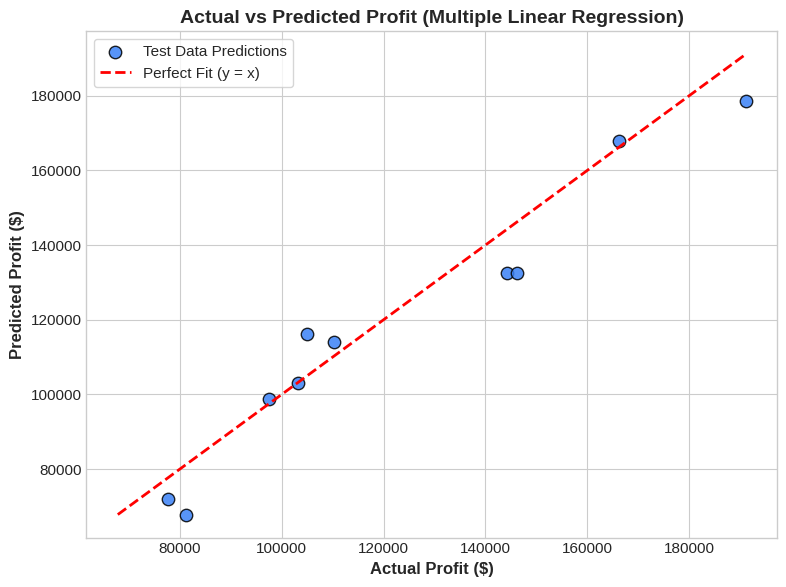

In [6]:
# Direct Execution of Problem 1
DEFAULT_DATASET = 'https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv'
run_problem_1(DEFAULT_DATASET)


🔬 [Part 2] Forward Feature Selection & Multi-Model Comparison Workflow

📥 Loading dataset from: https://raw.githubusercontent.com/Avik-Jain/100-Days-Of-ML-Code/master/datasets/50_Startups.csv
✅ Data successfully loaded from web.

⚙️ Executing Forward Selection Algorithm (k = 1 to 5)...

📋 Markdown Results Table (Forward Selection):


| Number of Features | Selected Features | RMSE | R-squared |
|---|---|---|---|
| 1 | `['R&D Spend']` | 8274.868018 | 0.946459 |
| 2 | `['R&D Spend', 'Marketing Spend']` | 8198.797191 | 0.947439 |
| 3 | `['R&D Spend', 'Marketing Spend', 'State_New York']` | 8309.059683 | 0.946015 |
| 4 | `['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida']` | 8409.916714 | 0.944697 |
| 5 | `['R&D Spend', 'Marketing Spend', 'State_New York', 'State_Florida', 'Administration']` | 9137.990153 | 0.934707 |


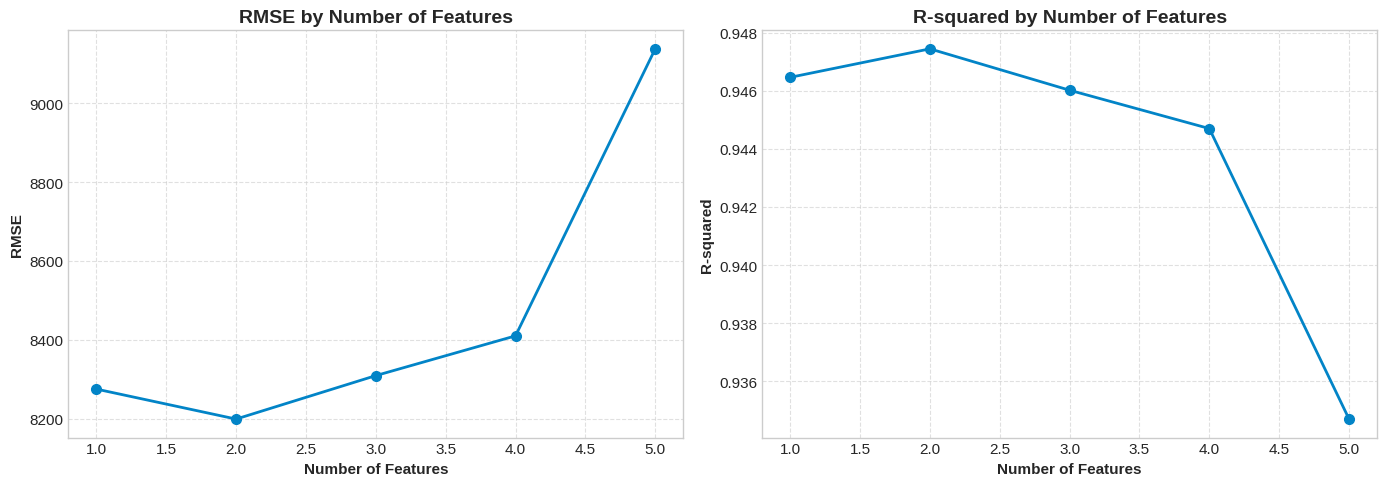


🤖 Executing Multi-Model Regression Comparison Workflow...

🏆 模型結果 (MSE 由小到大排序):


,Model,Features,MSE,RMSE,R2 Score
1,Gradient Boosting Regressor,['R&D Spend'],9.302162e+06,3049.944659,0.994157
0,Random Forest,['R&D Spend'],1.795017e+07,4236.764326,0.988725
4,Mutual Information,['R&D Spend'],8.512093e+07,9226.100548,0.946535
5,Ridge,['R&D Spend'],8.512093e+07,9226.100548,0.946535
7,Elastic Net,['R&D Spend'],8.512093e+07,9226.100548,0.946535
6,LASSO,['R&D Spend'],8.512093e+07,9226.100548,0.946535
3,SVM,['R&D Spend'],9.186839e+07,9584.799751,0.942297
2,SVR,['R&D Spend'],9.823650e+08,31342.702354,0.382974


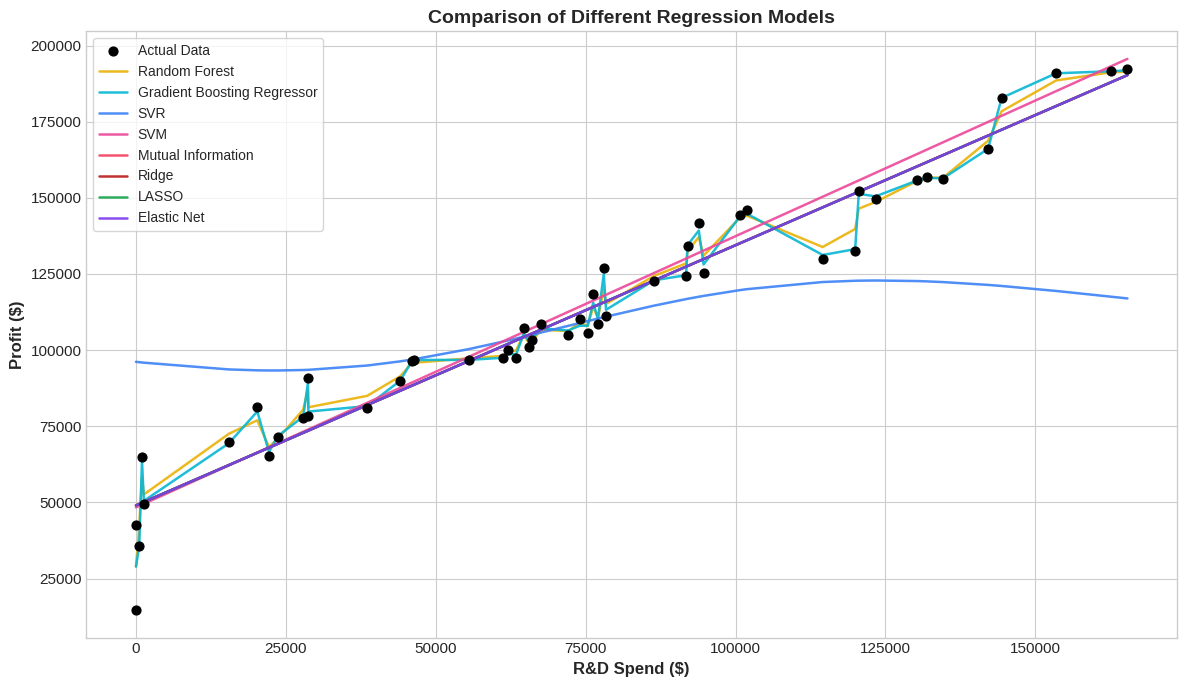

In [7]:
# Direct Execution of Problem 2
run_problem_2(DEFAULT_DATASET)
